# 06 — Grover: buscar sin índice

**Curso ECCI 2026 · Computación cuántica**

Hay una guía telefónica de $N$ nombres, desordenada, y un número. Queremos
saber de quién es. Clásicamente no hay nada mejor que mirar entrada por
entrada: en promedio $N/2$ consultas, en el peor caso $N$.

Grover (1996) lo hace en $O(\sqrt N)$. No es exponencial —Grover no rompe
RSA— pero es **demostrablemente óptimo**: ningún algoritmo cuántico puede
hacerlo mejor. Y a diferencia de Shor, no necesita ninguna estructura oculta
en el problema. Eso lo vuelve aplicable a cualquier búsqueda, incluida la de
soluciones de problemas NP.

Este notebook desarma el mecanismo y después lo rompe a propósito, porque el
error más instructivo de Grover es **pasarse de iteraciones**.

Recorrido:

1. El problema y la imagen geométrica: dos reflexiones son una rotación.
2. El oráculo: marcar con un **signo**, no con una probabilidad.
3. El difusor: inversión respecto del promedio.
4. $N = 8$: las amplitudes con signo, paso a paso.
5. **El sobrecocido**: qué pasa si se itera de más.
6. Escalado $N = 4, 8, 16, 32$ y la ley $k \approx \frac{\pi}{4}\sqrt N$.
7. Varios marcados a la vez.
8. Hardware real.

## Preámbulo: entorno

Esta celda no hace nada en el entorno local (el env `quantum`, que ya tiene
todo instalado). Solo actúa si el notebook corre en **Google Colab**, donde
instala lo que falta.

`plotly` e `ipywidgets` vienen con Colab, así que no se instalan.

**Sobre `utils.py`:** los notebooks importan ese módulo, que en el entorno
local está en la misma carpeta. En Colab la celda lo **baja solo** de un
archivo de Drive compartido como "cualquiera con el link puede ver", así que
funciona para cualquiera que abra el notebook sin que tenga que autenticarse.

Dos detalles de esa descarga:

- se usa el endpoint `drive.usercontent.google.com`, porque la URL clásica
  `uc?export=download` devuelve la página de aviso de antivirus en vez del
  archivo;
- solo baja si `utils` no está ya disponible, de modo que una **subida manual
  al panel de archivos tiene prioridad** sobre la copia de Drive.

Si el archivo de Drive se actualiza con *Administrar versiones*, el ID y el
link se mantienen, y los notebooks siguen apuntando al lugar correcto.

In [1]:
import importlib.util
import sys

try:                      # find_spec("google.colab") falla si no existe el padre
    import google.colab   # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !pip install qiskit
    !pip install qiskit-ibm-runtime
    !pip install qiskit_aer
    !pip install pylatexenc

    # utils.py desde Drive, compartido como "cualquiera con el link puede ver".
    # Se usa el endpoint drive.usercontent, que entrega el archivo directo; la
    # URL clásica uc?export=download devuelve la página de aviso de antivirus.
    # Solo se baja si no está ya presente, así una subida manual tiene prioridad.
    UTILS_ID = "1_VyKXtDMVqnJHcGepeARhoEY4tikLSDg"
    if importlib.util.find_spec("utils") is None:
        !wget -q -O utils.py "https://drive.usercontent.google.com/download?id=$UTILS_ID&export=download&confirm=t"
        importlib.invalidate_caches()
        if importlib.util.find_spec("utils") is None:
            print("No se pudo bajar utils.py: subirlo a mano desde el panel de archivos.")
        else:
            print("utils.py descargado de Drive")
else:
    print("entorno local: no hay nada que instalar")

try:
    import utils
    print(f"utils.py versión {utils.__version__}")
except ImportError:
    print("utils.py todavía no está disponible")

entorno local: no hay nada que instalar


utils.py versión 2026-09-19


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit
from qiskit.circuit.library import MCXGate
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_state_qsphere
from qiskit_ibm_runtime.fake_provider import FakeFez

import plotly.io as pio

import utils

utils.estilo()
pio.renderers.default = "plotly_mimetype"
fez = FakeFez()
SHOTS = 8192
MARCAS = "①②③④⑤⑥⑦⑧⑨"


def marca(qc, n):
    qc.barrier(label=MARCAS[n - 1])
    return qc


print("listo")

listo


## Autenticación (opcional, y en memoria)

In [3]:
from getpass import getpass

from qiskit_ibm_runtime import QiskitRuntimeService

CRN = "crn:v1:bluemix:public:quantum-computing:us-east:a/1a958fc8c19b451ba71d1d0d94d52a44:9153727a-cc43-46be-a974-dfe1f29b4bcb::"

AUTENTICAR = False

service = None
if AUTENTICAR:
    service = QiskitRuntimeService(channel="ibm_cloud",
                                   token=getpass("API key: "),
                                   instance=CRN)
    print([b.name for b in service.backends()])
else:
    print("sin autenticar — el notebook corre entero en simulador")

sin autenticar — el notebook corre entero en simulador


---
# 1. El problema, y la imagen que lo explica todo

Hay una función $f: \{0,1\}^n \to \{0,1\}$ que vale 1 solo para el elemento
buscado $\omega$, y 0 para los otros $N - 1 = 2^n - 1$. La función es una
**caja negra**: se la puede evaluar, no inspeccionar.

## La imagen geométrica

Todo Grover vive en un **plano de dos dimensiones**, y esto es lo que hay
que
entender antes de mirar un solo circuito.

Definí dos estados ortogonales:

$$|\omega\rangle \;=\; \text{el marcado},
\qquad
|\omega^\perp\rangle \;=\; \frac{1}{\sqrt{N-1}}\sum_{x \neq \omega}|x\rangle
\;=\; \text{la mezcla uniforme del resto}.$$

El estado inicial —la superposición uniforme $|s\rangle$— está casi pegado a
$|\omega^\perp\rangle$, formando con él un ángulo chiquito $\theta$:

$$\sin\theta = \frac{1}{\sqrt N} \;\;\Longrightarrow\;\;
  \theta \approx \frac{1}{\sqrt N}\ \text{(para $N$ grande)}.$$

Cada iteración de Grover hace **dos reflexiones**:

1. el **oráculo** refleja respecto de $|\omega^\perp\rangle$ (le da vuelta
el
   signo a la componente marcada),
2. el **difusor** refleja respecto de $|s\rangle$.

Y acá está el hecho clave de geometría elemental: **la composición de dos
reflexiones es una rotación**, de ángulo el doble del que forman los dos
ejes.
Así que cada iteración **rota el estado $2\theta$ hacia $|\omega\rangle$**.

Después de $k$ iteraciones el ángulo con $|\omega^\perp\rangle$ es
$(2k+1)\theta$, y por lo tanto

$$\boxed{\;P(\omega) = \sin^2\big((2k+1)\theta\big)\;}$$

Esto explica las tres cosas importantes de un saque:

- **Cuántas iteraciones**: se quiere $(2k+1)\theta \approx \pi/2$, o sea
  $k \approx \frac{\pi}{4}\sqrt N$. De ahí sale el $O(\sqrt N)$.
- **Por qué hay que parar**: la rotación no se detiene sola. Si se sigue, te
  se pasa de largo y la probabilidad **baja**. Eso es el sobrecocido.
- **Por qué es periódico**: $\sin^2$ oscila. Grover no converge: la
probabilidad oscila.

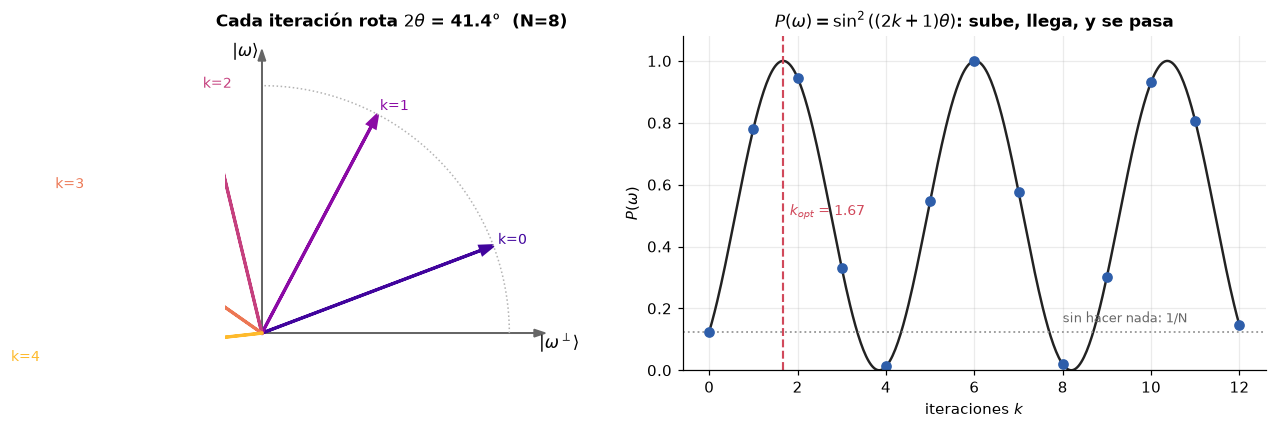

N = 8:  θ = 20.70°,  rotación por iteración = 41.41°
k óptimo (continuo) = 1.673  →  hay que usar k = 2
P(ω) con k=2: 0.9453   con k=3: 0.3301   con k=6: 0.9998  ← sobrecocido


In [4]:
# La imagen geométrica, dibujada.
N, n = 8, 3
theta = np.arcsin(1 / np.sqrt(N))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4),
                               gridspec_kw={"width_ratios": [1, 1.25]})
ax1.set_aspect("equal")
ax1.set_xlim(-0.15, 1.2); ax1.set_ylim(-0.15, 1.2)
ax1.arrow(0, 0, 1.1, 0, head_width=0.03, color="0.4", lw=1)
ax1.arrow(0, 0, 0, 1.1, head_width=0.03, color="0.4", lw=1)
ax1.text(1.12, -0.06, r"$|\omega^\perp\rangle$", fontsize=11)
ax1.text(-0.12, 1.12, r"$|\omega\rangle$", fontsize=11)
colores_it = plt.colormaps["plasma"](np.linspace(0.1, 0.85, 5))
for k in range(5):
    ang = (2 * k + 1) * theta
    ax1.arrow(0, 0, np.cos(ang), np.sin(ang), head_width=0.035,
              color=colores_it[k], lw=2, length_includes_head=True)
    ax1.text(1.02 * np.cos(ang), 1.02 * np.sin(ang), f"k={k}", fontsize=9,
             color=colores_it[k])
arco = np.linspace(0, np.pi / 2, 100)
ax1.plot(np.cos(arco), np.sin(arco), ":", color="0.7", lw=1)
ax1.set_title(f"Cada iteración rota $2\\theta$ = {np.degrees(2 * theta):.1f}°"
              f"  (N={N})")
ax1.axis("off")

ks = np.linspace(0, 12, 400)
ax2.plot(ks, np.sin((2 * ks + 1) * theta) ** 2, color=utils.COLOR_TEORIA, lw=1.6)
k_opt = np.pi / (4 * theta) - 0.5
ax2.axvline(k_opt, color=utils.COLOR_RUIDO, ls="--", lw=1.4)
ax2.text(k_opt + 0.15, 0.5, f"$k_{{opt}}$ = {k_opt:.2f}", fontsize=9,
         color=utils.COLOR_RUIDO)
ax2.axhline(1 / N, color="0.6", ls=":", lw=1.2)
ax2.text(8, 1 / N + 0.03, "sin hacer nada: 1/N", fontsize=8.5, color="0.4")
for k in range(13):
    ax2.plot(k, np.sin((2 * k + 1) * theta) ** 2, "o", ms=6,
             color=utils.COLOR_IDEAL)
ax2.set_xlabel("iteraciones $k$")
ax2.set_ylabel(r"$P(\omega)$")
ax2.set_ylim(0, 1.08)
ax2.set_title(r"$P(\omega) = \sin^2((2k+1)\theta)$: sube, llega, y se pasa")
utils.layout(fig)
plt.show()

print(f"N = {N}:  θ = {np.degrees(theta):.2f}°,  rotación por iteración = "
      f"{np.degrees(2 * theta):.2f}°")
print(f"k óptimo (continuo) = {k_opt:.3f}  →  hay que usar k = {round(k_opt)}")
print(f"P(ω) con k=2: {np.sin(5 * theta) ** 2:.4f}   con k=3: {np.sin(7 * theta) ** 2:.4f}"
      f"   con k=6: {np.sin(13 * theta) ** 2:.4f}  ← sobrecocido")

---
# 2. El oráculo: marcar con un signo

El oráculo tiene que señalar a $\omega$ sin que se note al medir —si se
notara, ya habríamos resuelto el problema—. La forma de hacerlo es con un
**signo**:

$$O\,|x\rangle = (-1)^{f(x)}|x\rangle
  \quad\Longrightarrow\quad
  \begin{cases} |x\rangle & x \neq \omega\\ -|x\rangle & x =
    \omega\end{cases}$$

**Una fase no cambia ninguna probabilidad.** Si se mide justo después del
oráculo, todos los resultados siguen siendo equiprobables: el oráculo, solo,
no hace absolutamente nada observable. Lo que hace es dejar una marca que el
paso siguiente sí puede aprovechar.

Para $\omega = 101$ con 3 qubits, el oráculo es: dar vuelta los qubits que
tienen que valer 0, aplicar una $Z$ multi-controlada, y deshacer.

Grover con N=8, ω=101, una iteración:


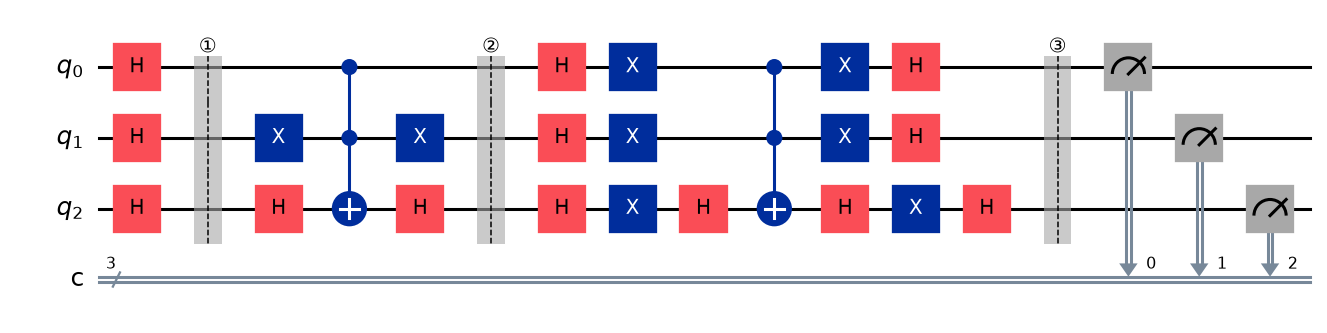

In [5]:
def oraculo(n: int, marcados) -> QuantumCircuit:
    """Cambia de signo los estados marcados. `marcados` es una lista de cadenas
    tipo '101' (el bit de la izquierda es el qubit n-1, como en los counts)."""
    qc = QuantumCircuit(n, name=f"oráculo {','.join(marcados)}")
    for w in marcados:
        ceros = [i for i in range(n) if w[n - 1 - i] == "0"]
        if ceros:
            qc.x(ceros)
        qc.h(n - 1)
        qc.append(MCXGate(n - 1), list(range(n)))   # MCX + H = MCZ
        qc.h(n - 1)
        if ceros:
            qc.x(ceros)
    return qc


def difusor(n: int) -> QuantumCircuit:
    """Inversión respecto del promedio: refleja el estado alrededor de |s>."""
    qc = QuantumCircuit(n, name="difusor")
    qc.h(range(n))
    qc.x(range(n))
    qc.h(n - 1)
    qc.append(MCXGate(n - 1), list(range(n)))
    qc.h(n - 1)
    qc.x(range(n))
    qc.h(range(n))
    return qc


def grover(n: int, marcados, k: int, medir=True) -> QuantumCircuit:
    """Grover completo con k iteraciones."""
    qc = QuantumCircuit(n, n) if medir else QuantumCircuit(n)
    qc.h(range(n))
    marca(qc, 1)
    for it in range(k):
        qc.compose(oraculo(n, marcados), range(n), inplace=True)
        marca(qc, 2 if it == 0 else 4)
        qc.compose(difusor(n), range(n), inplace=True)
        marca(qc, 3 if it == 0 else 5)
    if medir:
        qc.measure(range(n), range(n))
    return qc


OMEGA = "101"
print(f"Grover con N=8, ω={OMEGA}, una iteración:")
display(grover(3, [OMEGA], 1).draw("mpl", style="iqp", fold=-1))

### La cuenta, etapa por etapa ($N = 8$, $\omega = 101$)

Seguimos **las amplitudes con signo**, no las probabilidades — es la única
forma de ver el mecanismo. Llamemos $a_\omega$ a la amplitud del marcado,
$a_{\text{otros}}$ a la de cada uno de los otros siete, y $\bar a$ al
promedio
de las ocho.

**①** Dado que se aplican las $H$ a los tres qubits:
$$|\psi_1\rangle = \frac{1}{\sqrt8}\sum_{x=0}^{7}|x\rangle .$$
Las ocho amplitudes valen $1/\sqrt8 = 0.354$, y $P(\omega) = 1/8$. Tirar una
moneda de tres caras da lo mismo.

**②** Dado que se aplica el oráculo, que invierte el signo de la componente
marcada:
$$a_\omega = -0.354, \qquad a_{\text{otros}} = +0.354 .$$
**Ninguna probabilidad cambió**: los ocho $|a|^2$ siguen valiendo $1/8$.
Medir
acá no serviría absolutamente de nada. Pero el promedio sí cambió, y
bastante:
$$\bar a = \frac{7(0.354) - 0.354}{8} = 0.265 .$$
El signo negativo **arrastró el promedio hacia abajo**. Ese es todo el
aporte
del oráculo, y es invisible al medir.

**③** Dado que se aplica el difusor, que refleja cada amplitud alrededor del
promedio, $a \to 2\bar a - a$:
$$a_\omega = 2(0.265) - (-0.354) = \mathbf{0.884}, \qquad
  a_{\text{otros}} = 2(0.265) - 0.354 = 0.177 .$$
La amplitud marcada era la única negativa, así que la reflexión la manda muy
por encima de las otras. Ahora $P(\omega) = 0.884^2 = \mathbf{0.781}$.

**④** Dado que se aplica el oráculo por segunda vez:
$a_\omega = -0.884$, y el promedio se desploma a
$$\bar a = \frac{7(0.177) - 0.884}{8} = 0.044 .$$

**⑤** Dado que se aplica el difusor por segunda vez:
$$a_\omega = 2(0.044) + 0.884 = \mathbf{0.972}, \qquad
  a_{\text{otros}} = 2(0.044) - 0.177 = -0.088 .$$
$P(\omega) = 0.945$. **Y acá hay que parar**, porque las otras amplitudes ya
se pasaron a negativas: en la próxima vuelta el promedio se va a mover en la
dirección equivocada y la amplitud marcada va a empezar a bajar.

### Cómo llega al final, dicho de una

El oráculo **no amplifica nada**: solo marca con un signo, y eso baja el
promedio. El difusor **no sabe cuál es el marcado**: solo refleja todo
alrededor del promedio. La composición de los dos convierte "ser el único
negativo" en "ser el más alto", y repetirla rota el estado de a $2\theta$
hacia $|\omega\rangle$ — hasta pasarse.

---
# 3. El difusor: inversión respecto del promedio

El difusor es
$D = 2|s\rangle\langle s| - I$, la reflexión alrededor de la superposición
uniforme. Escrito en componentes hace algo muy concreto y fácil de ver:

$$\alpha_x \;\longrightarrow\; 2\bar\alpha - \alpha_x,
\qquad \bar\alpha = \frac{1}{N}\sum_y \alpha_y .$$

**Cada amplitud se refleja alrededor del promedio.** Y acá se ve por qué el
signo del oráculo importa tanto: después de marcar, la amplitud de $\omega$
es
negativa, así que **baja el promedio**; al reflejar alrededor de un promedio
bajo, la amplitud negativa salta muy por encima de las otras.

El oráculo solo no hacía nada. El difusor solo tampoco. Los dos juntos
convierten un signo en probabilidad.

### Las amplitudes con signo, paso a paso

Esta es la figura de la clase: hay que graficar **amplitudes** (con signo),
no
probabilidades, porque en las probabilidades el oráculo es invisible.

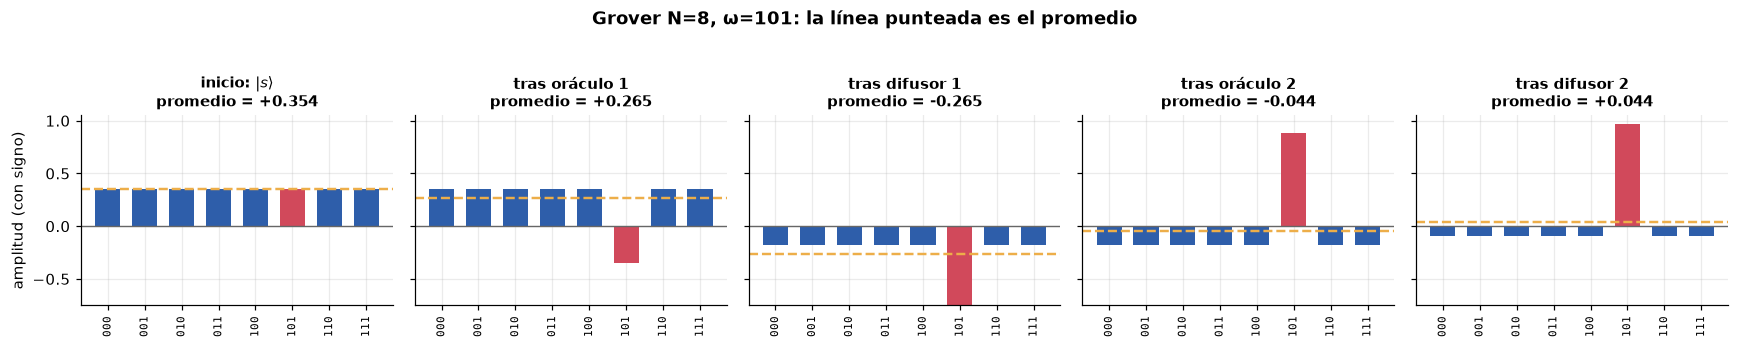

inicio: $|s\rangle$    amplitud de ω = +0.3536   promedio = +0.3536   P(ω) = 0.1250
tras oráculo 1         amplitud de ω = -0.3536   promedio = +0.2652   P(ω) = 0.1250
tras difusor 1         amplitud de ω = -0.8839   promedio = -0.2652   P(ω) = 0.7812
tras oráculo 2         amplitud de ω = +0.8839   promedio = -0.0442   P(ω) = 0.7812
tras difusor 2         amplitud de ω = +0.9723   promedio = +0.0442   P(ω) = 0.9453


In [6]:
def amplitudes_por_etapa(n, marcados, k_max=2):
    """Amplitudes reales después de cada media iteración."""
    etapas = []
    qc = QuantumCircuit(n)
    qc.h(range(n))
    etapas.append(("inicio: $|s\\rangle$", np.real(Statevector(qc).data.copy())))
    for it in range(k_max):
        qc.compose(oraculo(n, marcados), range(n), inplace=True)
        etapas.append((f"tras oráculo {it + 1}", np.real(Statevector(qc).data.copy())))
        qc.compose(difusor(n), range(n), inplace=True)
        etapas.append((f"tras difusor {it + 1}", np.real(Statevector(qc).data.copy())))
    return etapas


etapas = amplitudes_por_etapa(3, [OMEGA], k_max=2)
claves = utils.claves_completas(3)
idx_omega = int(OMEGA, 2)

fig, ejes = plt.subplots(1, len(etapas), figsize=(16, 3), sharey=True)
for ax, (titulo, amp) in zip(ejes, etapas):
    colores = [utils.COLOR_RUIDO if i == idx_omega else utils.COLOR_IDEAL
               for i in range(len(amp))]
    ax.bar(range(len(amp)), amp, color=colores, width=0.68)
    promedio = amp.mean()
    ax.axhline(promedio, color=utils.PALETA[3], lw=1.6, ls="--")
    ax.axhline(0, color="0.4", lw=0.9)
    ax.set_xticks(range(len(amp)))
    ax.set_xticklabels(claves, rotation=90, fontsize=7, family="monospace")
    ax.set_title(f"{titulo}\npromedio = {promedio:+.3f}", fontsize=9.5)
    ax.set_ylim(-0.75, 1.05)
ejes[0].set_ylabel("amplitud (con signo)")
fig.suptitle(f"Grover N=8, ω={OMEGA}: la línea punteada es el promedio",
             fontweight="bold", y=1.04)
utils.layout(fig)
plt.show()

for titulo, amp in etapas:
    print(f"{titulo:<22} amplitud de ω = {amp[idx_omega]:+.4f}   "
          f"promedio = {amp.mean():+.4f}   P(ω) = {amp[idx_omega] ** 2:.4f}")

Seguir la barra roja:

- **inicio**: todas iguales, $1/\sqrt8 = 0.354$. $P(\omega) = 1/8$.
- **tras el oráculo 1**: la roja se dio vuelta, $-0.354$. Todas las alturas
  al cuadrado siguen valiendo lo mismo: **medir acá no serviría de nada**.
  Pero el promedio bajó de $0.354$ a $0.265$.
- **tras el difusor 1**: reflejada alrededor de ese promedio bajo, la roja
  salta a $+0.884$. $P(\omega) = 0.781$. Las otras bajaron un poco.
- **tras el oráculo 2**: la roja se vuelve a dar vuelta.
- **tras el difusor 2**: $P(\omega) = 0.945$. Ya casi.

El mecanismo entero es eso: **el signo del oráculo baja el promedio, y el
difusor convierte esa asimetría en altura**.

### La Q-sphere, que muestra el signo

El signo del oráculo también se ve en el color de la Q-sphere. Es la
visualización que hace visible lo que el histograma esconde.

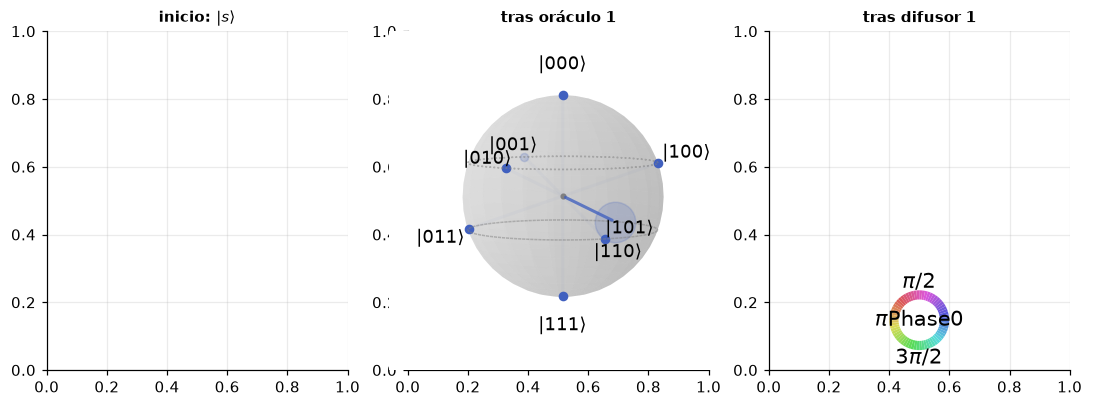

In [7]:
fig = plt.figure(figsize=(12, 4))
for i, (titulo, _) in enumerate(etapas[:3]):
    qc = QuantumCircuit(3)
    qc.h(range(3))
    if i >= 1:
        qc.compose(oraculo(3, [OMEGA]), range(3), inplace=True)
    if i >= 2:
        qc.compose(difusor(3), range(3), inplace=True)
    ax = fig.add_subplot(1, 3, i + 1)
    plot_state_qsphere(Statevector(qc), ax=ax, show_state_labels=True)
    ax.set_title(titulo, fontsize=10)
plt.show()

En el panel del medio, los ocho puntos siguen siendo **del mismo tamaño**
—las
probabilidades no cambiaron— pero uno cambió de **color**: esa es la fase
$-1$ del oráculo. En el tercero, ese punto creció y los otros se achicaron.

---
# 4. El sobrecocido

Grover no converge: la probabilidad **oscila**. Si se sigue aplicando
iteraciones después del
óptimo, la rotación se pasa de $|\omega\rangle$ y la probabilidad vuelve a
bajar. Es el error más común y el más instructivo, porque contradice la
intuición de que "más cómputo, mejor respuesta".

Con $N = 8$ el óptimo es $k = 2$. Vamos de 0 a 8 y miramos qué pasa.

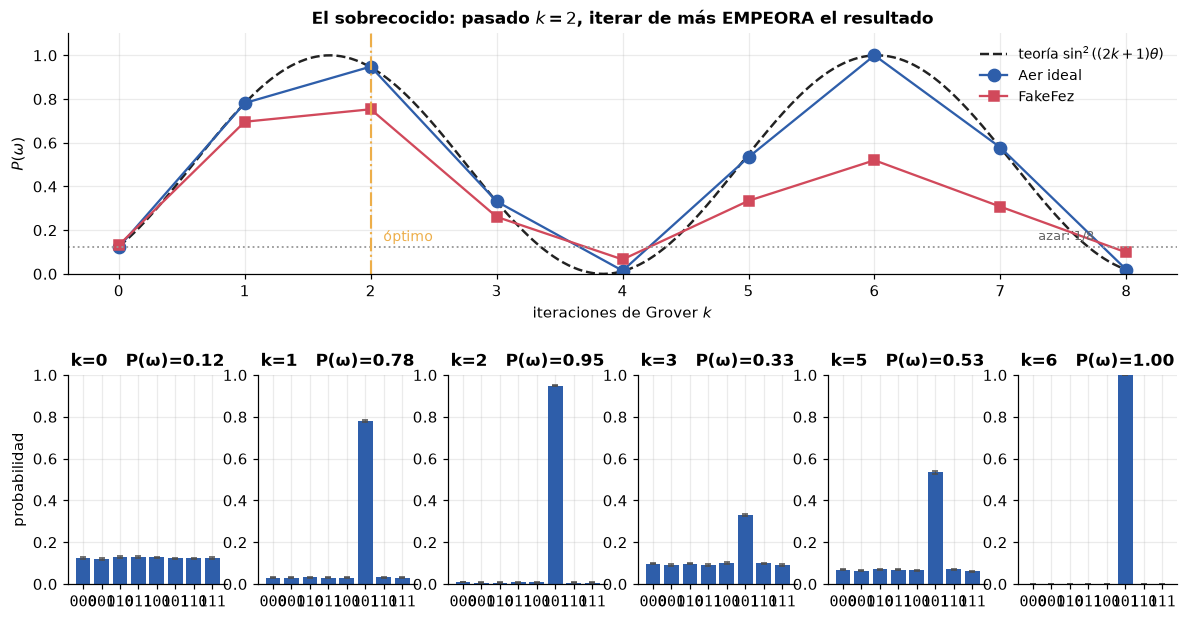

 k  P(ω) ideal  P(ω) teoría  P(ω) FakeFez
 0      0.1232       0.1250        0.1318  ← peor que no hacer nada
 1      0.7816       0.7812        0.6962
 2      0.9484       0.9453        0.7532  ← óptimo
 3      0.3314       0.3301        0.2609
 4      0.0145       0.0122        0.0659  ← peor que no hacer nada
 5      0.5341       0.5480        0.3345
 6      0.9999       0.9998        0.5199
 7      0.5781       0.5770        0.3075
 8      0.0193       0.0195        0.0981  ← peor que no hacer nada


In [8]:
KS = list(range(9))
circ_k = [grover(3, [OMEGA], k) for k in KS]
c_k_ideal = utils.correr_ideal(circ_k, shots=SHOTS)
c_k_ruido = utils.correr_ruidoso(circ_k, backend_falso=fez, shots=SHOTS)

p_omega_i = np.array([c.get(OMEGA, 0) / SHOTS for c in c_k_ideal])
p_omega_r = np.array([c.get(OMEGA, 0) / SHOTS for c in c_k_ruido])

fig = plt.figure(figsize=(13, 6.5))
gs = fig.add_gridspec(2, 1, height_ratios=[1.15, 1], hspace=0.45)

ax = fig.add_subplot(gs[0])
kk = np.linspace(0, 8, 400)
ax.plot(kk, np.sin((2 * kk + 1) * theta) ** 2, color=utils.COLOR_TEORIA, ls="--",
        lw=1.6, label=r"teoría $\sin^2((2k+1)\theta)$")
ax.plot(KS, p_omega_i, "o-", ms=8, color=utils.COLOR_IDEAL, label="Aer ideal")
ax.plot(KS, p_omega_r, "s-", ms=7, color=utils.COLOR_RUIDO, label="FakeFez")
ax.axhline(1 / 8, color="0.6", ls=":", lw=1.2)
ax.text(7.3, 1 / 8 + 0.03, "azar: 1/8", fontsize=8.5, color="0.4")
ax.axvline(2, color=utils.PALETA[3], lw=1.4, ls="-.")
ax.text(2.1, 0.15, "óptimo", fontsize=9, color=utils.PALETA[3])
ax.set_xlabel("iteraciones de Grover $k$")
ax.set_ylabel(r"$P(\omega)$")
ax.set_ylim(0, 1.1)
ax.set_title("El sobrecocido: pasado $k=2$, iterar de más EMPEORA el resultado",
             fontweight="bold")
ax.legend(fontsize=9)

for j, k in enumerate([0, 1, 2, 3, 5, 6]):
    ax = fig.add_subplot(gs[1].subgridspec(1, 6)[j])
    utils.comparar_conteos({"ideal": c_k_ideal[k]}, claves=claves, ax=ax,
                           titulo=f"k={k}   P(ω)={p_omega_i[k]:.2f}")
    ax.set_xlabel("")
    ax.get_legend().remove()
    if j:
        ax.set_ylabel("")
    ax.set_ylim(0, 1)
plt.show()

print(f"{'k':>2} {'P(ω) ideal':>11} {'P(ω) teoría':>12} {'P(ω) FakeFez':>13}")
for k, pi, pr in zip(KS, p_omega_i, p_omega_r):
    teo = np.sin((2 * k + 1) * theta) ** 2
    marca_txt = "  ← óptimo" if k == 2 else ("  ← peor que no hacer nada" if pi < 1 / 8 else "")
    print(f"{k:>2} {pi:>11.4f} {teo:>12.4f} {pr:>13.4f}{marca_txt}")

**Con $k = 6$ la probabilidad cae por debajo de $1/8$: peor que tirar una
moneda.** El algoritmo funcionó perfectamente, rotó exactamente lo que tenía
que rotar, y el resultado es basura porque rotó de más.

Esto tiene una consecuencia práctica fuerte: **para usar Grover hay que
conocer $N$ y la cantidad de soluciones $M$ de antemano**, para calcular
$k$. Si no se conocen, hay variantes (*exponential searching*, conteo por
amplitud) que las estiman primero.

En la curva con ruido pasa otra cosa: sigue la forma correcta pero achatada,
y el
achatamiento crece con $k$ porque cada iteración agrega profundidad. En
hardware real hay un segundo óptimo, distinto del teórico: el $k$ donde la
ganancia de rotación todavía le gana a la pérdida por decoherencia.

### Jugá con las iteraciones

In [9]:
def explorar_grover(iteraciones=2, n_qubits=3):
    n = int(n_qubits)
    N = 2 ** n
    omega = "1" * (n - 1) + "01"[:1] if n > 2 else "10"
    omega = format(N - 3 if N > 4 else 1, f"0{n}b")
    th = np.arcsin(1 / np.sqrt(N))
    c = utils.correr_ideal(grover(n, [omega], int(iteraciones)), shots=4096)
    cl = utils.claves_completas(n)
    fig, ax = plt.subplots(figsize=(max(6, 0.55 * N), 3.3))
    probs = [c.get(k, 0) / 4096 for k in cl]
    colores = [utils.COLOR_RUIDO if k == omega else utils.COLOR_IDEAL for k in cl]
    ax.bar(range(N), probs, color=colores, width=0.7)
    ax.axhline(1 / N, color="0.5", ls=":", lw=1.2)
    k_op = round(np.pi / (4 * th) - 0.5)
    ax.set_xticks(range(N))
    ax.set_xticklabels(cl, rotation=90, fontsize=7, family="monospace")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("probabilidad")
    ax.set_title(f"N={N}, ω={omega}, k={int(iteraciones)} "
                 f"(óptimo {k_op}) → P(ω) = {c.get(omega, 0) / 4096:.3f}"
                 f"   ·   teoría {np.sin((2 * int(iteraciones) + 1) * th) ** 2:.3f}")
    plt.show()


utils.deslizador(explorar_grover, iteraciones=(0, 12, 1), n_qubits=[2, 3, 4, 5])

interactive(children=(IntSlider(value=2, description='iteraciones', max=12), Dropdown(description='n_qubits', …

interactive(children=(IntSlider(value=2, description='iteraciones', max=12), Dropdown(description='n_qubits', …

---
# 5. Escalado: la ley $\sqrt N$

Subimos $N$ y medimos cuántas iteraciones hacen falta. La predicción es
$k_{opt} \approx \frac{\pi}{4}\sqrt N$, y con ella el $O(\sqrt N)$ del
algoritmo.

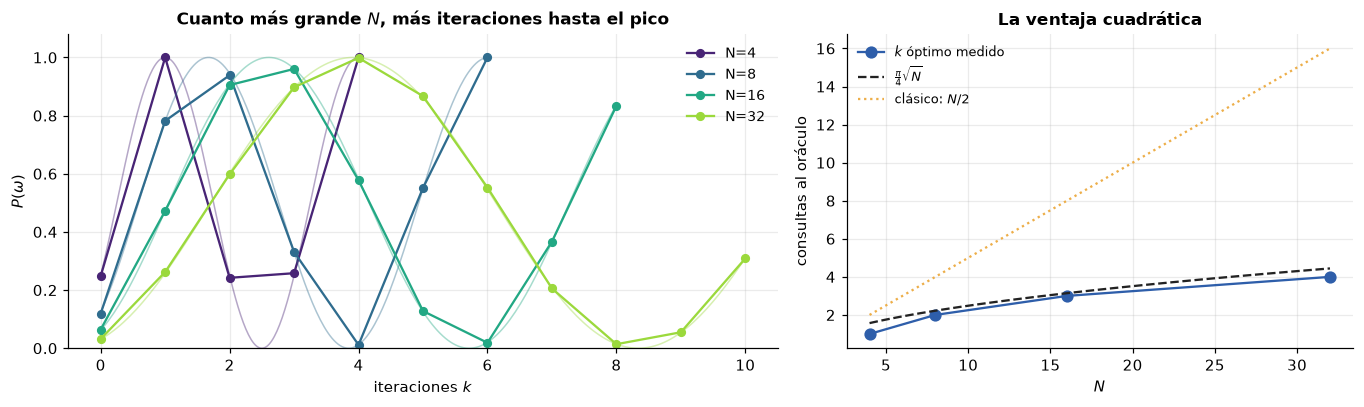

 n    N  k opt   π√N/4  P ideal  P FakeFez  prof.
 2    4      1    1.57    1.000      0.950     14
 3    8      2    2.22    0.947      0.752     22
 4   16      3    3.14    0.958      0.489     32
 5   32      4    4.44    0.999      0.095     42


In [10]:
NS_GROVER = [2, 3, 4, 5]     # qubits → N = 4, 8, 16, 32
resumen = []
curvas = {}
for n in NS_GROVER:
    N = 2 ** n
    th = np.arcsin(1 / np.sqrt(N))
    k_op = round(np.pi / (4 * th) - 0.5)
    omega = format(N - 3, f"0{n}b")
    ks = list(range(0, min(2 * k_op + 3, 14)))
    cs = utils.correr_ideal([grover(n, [omega], k) for k in ks], shots=4096)
    ps = [c.get(omega, 0) / 4096 for c in cs]
    curvas[n] = (ks, ps, th)
    c_opt = utils.correr_ideal(grover(n, [omega], k_op), shots=4096)
    c_opt_r = utils.correr_ruidoso(grover(n, [omega], k_op), backend_falso=fez,
                                   shots=4096)
    resumen.append((n, N, k_op, np.pi / 4 * np.sqrt(N),
                    c_opt.get(omega, 0) / 4096, c_opt_r.get(omega, 0) / 4096,
                    grover(n, [omega], k_op).depth()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.8),
                               gridspec_kw={"width_ratios": [1.4, 1]})
colores_n = plt.colormaps["viridis"](np.linspace(0.1, 0.85, len(NS_GROVER)))
for i, n in enumerate(NS_GROVER):
    ks, ps, th = curvas[n]
    kk = np.linspace(0, max(ks), 200)
    ax1.plot(kk, np.sin((2 * kk + 1) * th) ** 2, "-", lw=1, alpha=0.4,
             color=colores_n[i])
    ax1.plot(ks, ps, "o-", ms=5, color=colores_n[i], label=f"N={2 ** n}")
ax1.set_xlabel("iteraciones $k$")
ax1.set_ylabel(r"$P(\omega)$")
ax1.set_ylim(0, 1.08)
ax1.set_title("Cuanto más grande $N$, más iteraciones hasta el pico")
ax1.legend(fontsize=9)

Ns = [r[1] for r in resumen]
ax2.plot(Ns, [r[2] for r in resumen], "o-", ms=7, color=utils.COLOR_IDEAL,
         label="$k$ óptimo medido")
nn = np.linspace(4, 32, 100)
ax2.plot(nn, np.pi / 4 * np.sqrt(nn), "--", color=utils.COLOR_TEORIA,
         label=r"$\frac{\pi}{4}\sqrt{N}$")
ax2.plot(nn, nn / 2, ":", color=utils.PALETA[3], label="clásico: $N/2$")
ax2.set_xlabel("$N$")
ax2.set_ylabel("consultas al oráculo")
ax2.set_title("La ventaja cuadrática")
ax2.legend(fontsize=8.5)
utils.layout(fig)
plt.show()

print(f"{'n':>2} {'N':>4} {'k opt':>6} {'π√N/4':>7} {'P ideal':>8} {'P FakeFez':>10} {'prof.':>6}")
for n, N, k_op, k_teo, p_i, p_r, prof in resumen:
    print(f"{n:>2} {N:>4} {k_op:>6} {k_teo:>7.2f} {p_i:>8.3f} {p_r:>10.3f} {prof:>6}")

**La columna de FakeFez es la que baja el entusiasmo.** El $k$ óptimo crece
como $\sqrt N$, pero la profundidad del circuito crece con $k$ *y* con el
costo de la $Z$ multi-controlada, que se dispara con $n$. Para $N = 32$ el
circuito ya tiene cientos de compuertas de dos qubits y el ruido anula la ventaja.

Ese es el estado real de Grover en NISQ: **funciona bien hasta $N = 8$, se
defiende en $N = 16$, y de ahí en más necesita corrección de errores**.

---
# 6. Varios marcados

Si hay $M$ soluciones en vez de una, la geometría es la misma pero el ángulo
cambia:

$$\sin\theta = \sqrt{\frac{M}{N}}
  \quad\Longrightarrow\quad
  k_{opt} \approx \frac{\pi}{4}\sqrt{\frac{N}{M}}.$$

**Más soluciones = menos iteraciones.** Tiene sentido: el estado inicial ya
está más cerca del subespacio marcado. Y tiene una consecuencia rara: si no
se sabe $M$, no se sabe cuándo parar, y parar mal devuelve basura.

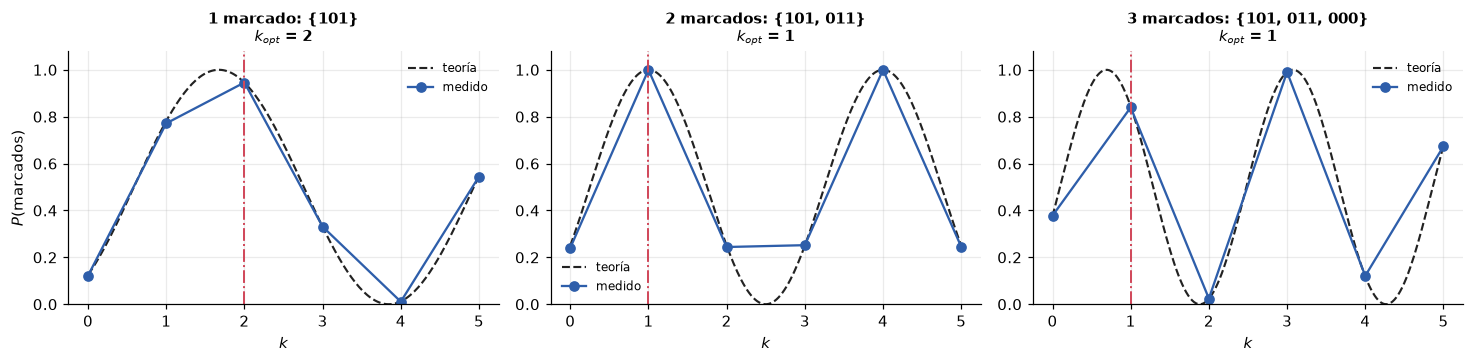

1 marcado: {101}                 θ =  20.7°   k_opt = 1.67
2 marcados: {101, 011}           θ =  30.0°   k_opt = 1.00
3 marcados: {101, 011, 000}      θ =  37.8°   k_opt = 0.69


In [11]:
CASOS_M = {"1 marcado: {101}": ["101"],
           "2 marcados: {101, 011}": ["101", "011"],
           "3 marcados: {101, 011, 000}": ["101", "011", "000"]}

fig, ejes = plt.subplots(1, 3, figsize=(13.5, 3.4))
for ax, (titulo, ms) in zip(ejes, CASOS_M.items()):
    M = len(ms)
    th_m = np.arcsin(np.sqrt(M / 8))
    k_op = max(1, round(np.pi / (4 * th_m) - 0.5))
    ks = list(range(6))
    cs = utils.correr_ideal([grover(3, ms, k) for k in ks], shots=4096)
    p_tot = [sum(c.get(w, 0) for w in ms) / 4096 for c in cs]
    kk = np.linspace(0, 5, 200)
    ax.plot(kk, np.sin((2 * kk + 1) * th_m) ** 2, "--", color=utils.COLOR_TEORIA,
            lw=1.4, label="teoría")
    ax.plot(ks, p_tot, "o-", ms=6, color=utils.COLOR_IDEAL, label="medido")
    ax.axvline(k_op, color=utils.COLOR_RUIDO, ls="-.", lw=1.3)
    ax.set_xlabel("$k$")
    ax.set_ylabel(r"$P(\rm{marcados})$" if ax is ejes[0] else "")
    ax.set_ylim(0, 1.08)
    ax.set_title(f"{titulo}\n$k_{{opt}}$ = {k_op}", fontsize=9.5)
    ax.legend(fontsize=8)
utils.layout(fig)
plt.show()

for titulo, ms in CASOS_M.items():
    M = len(ms)
    th_m = np.arcsin(np.sqrt(M / 8))
    print(f"{titulo:<32} θ = {np.degrees(th_m):5.1f}°   "
          f"k_opt = {np.pi / (4 * th_m) - 0.5:.2f}")

Con 2 marcados de 8, $k_{opt}$ cae de 2 a 1. Con 3, queda en 1 y ya con
$k=2$
te se pasa. La ventana se angosta rápido.

---
# 7. Hardware real

Grover con $N = 8$ es de las demostraciones que sí sobreviven a NISQ, y el
barrido de $k$ es perfecto para un solo job: **un circuito por valor de $k$,
todos juntos**.

In [12]:
if service is not None:
    print(f"{'backend':<16} {'qubits':>6} {'cola':>6}  {'estado':<10}")
    print("-" * 46)
    for b in service.backends(simulator=False):
        st = b.status()
        print(f"{b.name:<16} {b.num_qubits:>6} {st.pending_jobs:>6}  {st.status_msg:<10}")
else:
    print("sin autenticar")

sin autenticar


In [13]:
BACKEND_FIJO = None

backend = None
if service is not None:
    backend = (service.backend(BACKEND_FIJO) if BACKEND_FIJO
               else service.least_busy(operational=True, simulator=False))
    st = backend.status()
    print(f"elegido: {backend.name}  ·  {st.status_msg}  ·  cola {st.pending_jobs}")
else:
    print("sin autenticar: no hay backend")

sin autenticar: no hay backend


In [14]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

SHOTS_HW = 4096
KS_HW = [0, 1, 2, 3, 4, 5]
t_grover = None

if backend is not None:
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
    circuitos_hw = ([grover(3, [OMEGA], k) for k in KS_HW] +
                    [grover(3, ["101", "011"], k) for k in (1, 2)])
    t_grover = pm.run(circuitos_hw)
    print("=== Grover: barrido de k + 2 marcados ===")
    costo = utils.informe_transpilacion(t_grover, shots=SHOTS_HW,
                                        nombre_backend=backend.name)
else:
    print("sin backend: nada que transpilar")

sin backend: nada que transpilar


### El envío

Ocho circuitos en un job: $k = 0$ a $5$ con un marcado, más $k = 1, 2$ con
dos
marcados. Con eso sale la curva del sobrecocido medida en un chip real, que
es la figura para proyectar.

In [15]:
ENVIAR_GROVER = False   # ponerlo en True para gastar QPU

if ENVIAR_GROVER:
    from qiskit_ibm_runtime import SamplerV2

    job = SamplerV2(mode=backend).run(t_grover, shots=SHOTS_HW)
    utils.registrar_job(job, backend.name,
                        f"06 Grover N=8: k={KS_HW} + 2 marcados, {SHOTS_HW} shots",
                        notebook="06", experimento="grover",
                        n_circuitos=len(t_grover), shots=SHOTS_HW,
                        omega=OMEGA, ks=KS_HW)
else:
    print("modo simulación — no se envió nada")

modo simulación — no se envió nada


In [16]:
registros = utils.listar_jobs(filtro="06 ")

In [17]:
JOB_ID = ""   # vacío = el último job de Grover

if not JOB_ID:
    reg = utils.ultimo_job(experimento="grover")
    JOB_ID = reg["job_id"] if reg else ""
    if reg:
        print(f"último: {JOB_ID}  ({reg['backend']}, {reg['fecha']})")

if JOB_ID and service is not None:
    res = utils.recuperar(service, JOB_ID).result()
    hw = [utils.counts_de_resultado(res, i) for i in range(len(res))]
    p_hw = [c.get(OMEGA, 0) / sum(c.values()) for c in hw[:len(KS_HW)]]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.8),
                                   gridspec_kw={"width_ratios": [1.3, 1]})
    kk = np.linspace(0, max(KS_HW), 300)
    ax1.plot(kk, np.sin((2 * kk + 1) * theta) ** 2, "--", color=utils.COLOR_TEORIA,
             lw=1.5, label="teoría")
    ax1.plot(KS_HW, p_omega_i[:len(KS_HW)], "o-", ms=6, color=utils.COLOR_IDEAL,
             label="Aer ideal")
    ax1.plot(KS_HW, p_omega_r[:len(KS_HW)], "s-", ms=6, color=utils.COLOR_RUIDO,
             label="FakeFez")
    ax1.plot(KS_HW, p_hw, "D-", ms=7, color=utils.COLOR_HARD, label="hardware")
    ax1.axhline(1 / 8, color="0.6", ls=":", lw=1.2)
    ax1.set_xlabel("iteraciones $k$"); ax1.set_ylabel(r"$P(\omega)$")
    ax1.set_ylim(0, 1.08)
    ax1.set_title("El sobrecocido, medido en un chip real")
    ax1.legend(fontsize=8.5)

    k_mejor = int(np.argmax(p_hw))
    utils.comparar_conteos({"ideal": c_k_ideal[k_mejor], "hardware": hw[k_mejor]},
                           claves=claves, ax=ax2,
                           titulo=f"k = {k_mejor} (el mejor en hardware)")
    utils.layout(fig)
    plt.show()

    print(f"{'k':>2} {'P(ω) hardware':>14}")
    for k, p in zip(KS_HW, p_hw):
        print(f"{k:>2} {p:>14.4f}")
    print(f"\nmejor k en hardware: {k_mejor}  (teoría: 2)")
    print(f"ventaja sobre el azar: {max(p_hw) / (1 / 8):.1f}×")
else:
    print("sin JOB_ID o sin autenticar: nada que recuperar")

sin JOB_ID o sin autenticar: nada que recuperar


---
## Qué quedó establecido

1. **Grover es una rotación en un plano de dos dimensiones.** Dos
reflexiones
   —oráculo y difusor— componen una rotación de $2\theta$ por iteración.
2. **El oráculo solo no hace nada observable**: marca con un signo, y las
   probabilidades no cambian. Hay que graficar amplitudes para verlo.
3. **El difusor convierte ese signo en altura**, reflejando alrededor del
   promedio que el propio signo bajó.
4. $P(\omega) = \sin^2((2k+1)\theta)$, con $k_{opt} \approx
\frac{\pi}{4}\sqrt N$:
   de ahí sale la ventaja cuadrática.
5. **El sobrecocido es real y es grande**: con $k = 6$ y $N = 8$, Grover funciona peor que una moneda. Hay que saber cuándo parar.
6. Con $M$ marcados, $k_{opt} \approx \frac{\pi}{4}\sqrt{N/M}$: más
soluciones,
   menos iteraciones, ventana más angosta.

**Siguiente:** `07_qft_iqft.ipynb` — la transformada que hace posible QPE, y
el lío del orden de los bits.